# Подготовительные моменты

Подключение необходимых библиотек.

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.cluster import DBSCAN, KMeans
from sklearn.decomposition import PCA
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.preprocessing import LabelEncoder
from wordcloud import WordCloud
sns.set_theme()

Создание DataFrame из json-файла с данными о рецептах.

In [4]:
recipes = pd.read_json("train.json")

# Первый взгляд на набор данных

Набор данных о рецептах содержит следующие признаки:
- `id` - уникальный идентификационный номер рецепта;
- `cuisine` - принадлежность рецепта к какой-либо кухне;
- `ingredients` - список ингредиентов данного рецепта.

In [5]:
recipes

,id,cuisine,ingredients
0,10259,greek,"[romaine lettuce, black olives, grape tomatoes..."
1,25693,southern_us,"[plain flour, ground pepper, salt, tomatoes, g..."
2,20130,filipino,"[eggs, pepper, salt, mayonaise, cooking oil, g..."
3,22213,indian,"[water, vegetable oil, wheat, salt]"
4,13162,indian,"[black pepper, shallots, cornflour, cayenne pe..."
...,...,...,...
39769,29109,irish,"[light brown sugar, granulated sugar, butter, ..."
39770,11462,italian,"[KRAFT Zesty Italian Dressing, purple onion, b..."
39771,2238,irish,"[eggs, citrus fruit, raisins, sourdough starte..."
39772,41882,chinese,"[boneless chicken skinless thigh, minced garli..."


# Подготовка данных к кластеризации

Удаление столбца `id`, содержащего уникальный идентификационный номер рецепта, не имеющего смысла при решении поставленной задачи.

In [ ]:
recipes.drop(columns=["id"], inplace=True)
recipes

,cuisine,ingredients
0,greek,"[romaine lettuce, black olives, grape tomatoes..."
1,southern_us,"[plain flour, ground pepper, salt, tomatoes, g..."
2,filipino,"[eggs, pepper, salt, mayonaise, cooking oil, g..."
3,indian,"[water, vegetable oil, wheat, salt]"
4,indian,"[black pepper, shallots, cornflour, cayenne pe..."
...,...,...
39769,irish,"[light brown sugar, granulated sugar, butter, ..."
39770,italian,"[KRAFT Zesty Italian Dressing, purple onion, b..."
39771,irish,"[eggs, citrus fruit, raisins, sourdough starte..."
39772,chinese,"[boneless chicken skinless thigh, minced garli..."


Проверка набора данных на наличие пропусков.

In [ ]:
recipes.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 39774 entries, 0 to 39773
Data columns (total 2 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   cuisine      39774 non-null  object
 1   ingredients  39774 non-null  object
dtypes: object(2)
memory usage: 621.6+ KB


Просмотр количества рецептов, относящихся к каждой кухне.

In [ ]:
print(recipes.cuisine.value_counts())

cuisine
italian         7838
mexican         6438
southern_us     4320
indian          3003
chinese         2673
french          2646
cajun_creole    1546
thai            1539
japanese        1423
greek           1175
spanish          989
korean           830
vietnamese       825
moroccan         821
british          804
filipino         755
irish            667
jamaican         526
russian          489
brazilian        467
Name: count, dtype: int64


Отделение истинной метки — кухни.

In [ ]:
y = recipes.cuisine
y

,cuisine
0,greek
1,southern_us
2,filipino
3,indian
4,indian
...,...
39769,irish
39770,italian
39771,irish
39772,chinese


Кодирование истинных меток с помощью `LabelEncoder`.

In [ ]:
label_encoder = LabelEncoder()
y_true = label_encoder.fit_transform(y)
y_true

array([ 6, 16,  4, ...,  8,  3, 13])

Отеделение данных для кластеризации — ингредиентов.

In [ ]:
X = recipes.ingredients
X

,ingredients
0,"[romaine lettuce, black olives, grape tomatoes..."
1,"[plain flour, ground pepper, salt, tomatoes, g..."
2,"[eggs, pepper, salt, mayonaise, cooking oil, g..."
3,"[water, vegetable oil, wheat, salt]"
4,"[black pepper, shallots, cornflour, cayenne pe..."
...,...
39769,"[light brown sugar, granulated sugar, butter, ..."
39770,"[KRAFT Zesty Italian Dressing, purple onion, b..."
39771,"[eggs, citrus fruit, raisins, sourdough starte..."
39772,"[boneless chicken skinless thigh, minced garli..."


Преобразование списков ингредиентов в строки, где ингредиенты разделены точкой с запятой.

In [ ]:
X = X.apply(lambda x: ";".join(map(str, x)))
X

,ingredients
0,romaine lettuce;black olives;grape tomatoes;ga...
1,plain flour;ground pepper;salt;tomatoes;ground...
2,eggs;pepper;salt;mayonaise;cooking oil;green c...
3,water;vegetable oil;wheat;salt
4,black pepper;shallots;cornflour;cayenne pepper...
...,...
39769,light brown sugar;granulated sugar;butter;warm...
39770,KRAFT Zesty Italian Dressing;purple onion;broc...
39771,eggs;citrus fruit;raisins;sourdough starter;fl...
39772,boneless chicken skinless thigh;minced garlic;...


# Разбиение на ингредиенты

Использование `CountVectorizer` для получения разреженной матрицы, строки которой обозначают рецепты, а столбцы — ингредиенты. Элементами матрицы являются числа `1` или `0`, обозначающие соответственно содержится ли какой-либо ингредиент в очередном рецепте или нет.

In [ ]:
count_vectorizer = CountVectorizer(tokenizer=lambda x: x.split(";"), token_pattern=None)
X_csr = count_vectorizer.fit_transform(X)
X_csr

<Compressed Sparse Row sparse matrix of dtype 'int64'
	with 428249 stored elements and shape (39774, 6703)>

Создание `DataFrame`, содержащего все уникальные ингредиенты, полученные с помощью `CountVectorizer`. Добавление столбца, содержащего количество вхождений каждого ингредиента в набор данных. Сортировка игредиентов по частоте и вывод десяти ингредиентов, наиболее часто встречающихся в этом наборе данных.

In [ ]:
ingredients = pd.DataFrame(count_vectorizer.get_feature_names_out(), columns=["ingredient"])
ingredients["frequency"] = X_csr.sum(axis=0).T
ingredients.sort_values("frequency", ascending=False, inplace=True)
ingredients.reset_index(drop=True, inplace=True)
ingredients.head(10)

,ingredient,frequency
0,salt,18049
1,olive oil,7972
2,onions,7972
3,water,7457
4,garlic,7380
5,sugar,6434
6,garlic cloves,6237
7,butter,4848
8,ground black pepper,4785
9,all-purpose flour,4632


Чаще всего в рецептах встречаются следующие игредиенты: `salt` (соль), `olive oil` (оливковое масло), `onions` (лук), `water` (вода), `garlic` (чеснок), `sugar` (сахар), `garlic cloves` (зубчики чеснока), `butter` (сливочное масло), `ground black pepper` (чёрный молотый перец), `all-purpose flour` (мука высшего сорта).

## Кластеризация методом k-средних

Обучение `KMeans` на полученной разреженной матрице с разделением на 2 кластера. Копирование набора данных и добавление столбца, обозначающего кластер, в который был отнесён рецепт. Просмотр количества рецептов, попавших в каждый кластер.

In [ ]:
n_clusters = 2
kmeans_2 = KMeans(n_clusters=n_clusters, random_state=1)
y_pred = kmeans_2.fit_predict(X_csr)
recipes_clustered_2 = recipes.copy()
recipes_clustered_2["cluster"] = y_pred
recipes_clustered_2.cluster.value_counts()

,count
cluster,
0,21726
1,18048


Просмотр распределения рецептов каждой кухни по полученным кластерам.

In [ ]:
cuisines = pd.DataFrame(sorted(recipes.cuisine.unique()), columns=["cuisine"])
for i in range(n_clusters):
    cuisines_counts = recipes_clustered_2[recipes_clustered_2.cluster == i].cuisine.value_counts()
    cuisines_i = pd.DataFrame([cuisines_counts.index, cuisines_counts.values]).T
    cuisines_i.rename(columns={0: "cuisine", 1: f"cluster_{i}"}, inplace=True)
    cuisines = pd.merge(cuisines, cuisines_i, on="cuisine")
print(cuisines)

         cuisine cluster_0 cluster_1
0      brazilian       273       194
1        british       397       407
2   cajun_creole       803       743
3        chinese      1766       907
4       filipino       334       421
5         french      1443      1203
6          greek       604       571
7         indian      1069      1934
8          irish       291       376
9        italian      4384      3454
10      jamaican       194       332
11      japanese      1001       422
12        korean       577       253
13       mexican      3718      2720
14      moroccan       408       413
15       russian       201       288
16   southern_us      2030      2290
17       spanish       529       460
18          thai      1143       396
19    vietnamese       561       264


При разбиении на 2 кластера рецепты большинства кухонь примерно в равном количестве попали в каждый кластер.

Аналогичное получение разреженных матриц ингредиентов для кластеров `0` и `1` по отдельности.

In [ ]:
recipes_0 = recipes_clustered_2[recipes_clustered_2.cluster == 0]
recipes_0.reset_index(drop=True, inplace=True)
X_0 = recipes_0.ingredients.apply(lambda x: ";".join(map(str, x)))
count_vectorizer_0 = CountVectorizer(tokenizer=lambda x: x.split(";"), token_pattern=None)
X_csr_0 = count_vectorizer_0.fit_transform(X_0)
X_csr_0

<Compressed Sparse Row sparse matrix of dtype 'int64'
	with 212851 stored elements and shape (21726, 5847)>

In [ ]:
recipes_1 = recipes_clustered_2[recipes_clustered_2.cluster == 1]
recipes_1.reset_index(drop=True, inplace=True)
X_1 = recipes_1.ingredients.apply(lambda x: ";".join(map(str, x)))
count_vectorizer_1 = CountVectorizer(tokenizer=lambda x: x.split(";"), token_pattern=None)
X_csr_1 = count_vectorizer_1.fit_transform(X_1)
X_csr_1

<Compressed Sparse Row sparse matrix of dtype 'int64'
	with 215398 stored elements and shape (18048, 4876)>

Аналогичный вывод десяти ингредиентов, наиболее часто встречающихся в каждом кластере.

In [ ]:
ingredients_0 = pd.DataFrame(count_vectorizer_0.get_feature_names_out(), columns=["ingredient"])
ingredients_0["frequency"] = X_csr_0.sum(axis=0).T
ingredients_0.sort_values("frequency", ascending=False, inplace=True)
ingredients_0.reset_index(drop=True, inplace=True)
ingredients_0.head(10)

,ingredient,frequency
0,olive oil,3794
1,garlic,3631
2,onions,3580
3,water,3497
4,sugar,3373
5,garlic cloves,3241
6,kosher salt,2957
7,vegetable oil,2284
8,soy sauce,2231
9,butter,2071


Чаще всего в рецептах кластера `0` встречаются следующие игредиенты: `olive oil` (оливковое масло), `garlic` (чеснок), `onions` (лук), `water` (вода), `sugar` (сахар), `garlic cloves` (зубчики чеснока), `kosher salt` (поваренная соль), `vegetable oil` (растительное масло), `soy sauce` (соевый соус), `butter` (сливочное масло).

In [ ]:
ingredients_1 = pd.DataFrame(count_vectorizer_1.get_feature_names_out(), columns=["ingredient"])
ingredients_1["frequency"] = X_csr_1.sum(axis=0).T
ingredients_1.sort_values("frequency", ascending=False, inplace=True)
ingredients_1.reset_index(drop=True, inplace=True)
ingredients_1.head(10)

,ingredient,frequency
0,salt,18049
1,onions,4392
2,olive oil,4178
3,water,3960
4,pepper,3844
5,garlic,3749
6,all-purpose flour,3079
7,sugar,3061
8,garlic cloves,2996
9,butter,2777


Чаще всего в рецептах кластера `1` встречаются следующие игредиенты: `salt` (соль), `onions` (лук), `olive oil` (оливковое масло), `water` (вода), `pepper` (перец), `garlic` (чеснок), `all-purpose flour` (мука высшего сорта), `sugar` (сахар), `garlic cloves` (зубчики чеснока), `butter` (сливочное масло).

Таким образом, рецепты разделились по принципу: используется ли в них обычная соль или нет.

## Визуализация разбиения с помощью облаков слов

Генерация изображений облаков слов из полученных списков ингредиентов для каждого кластера.

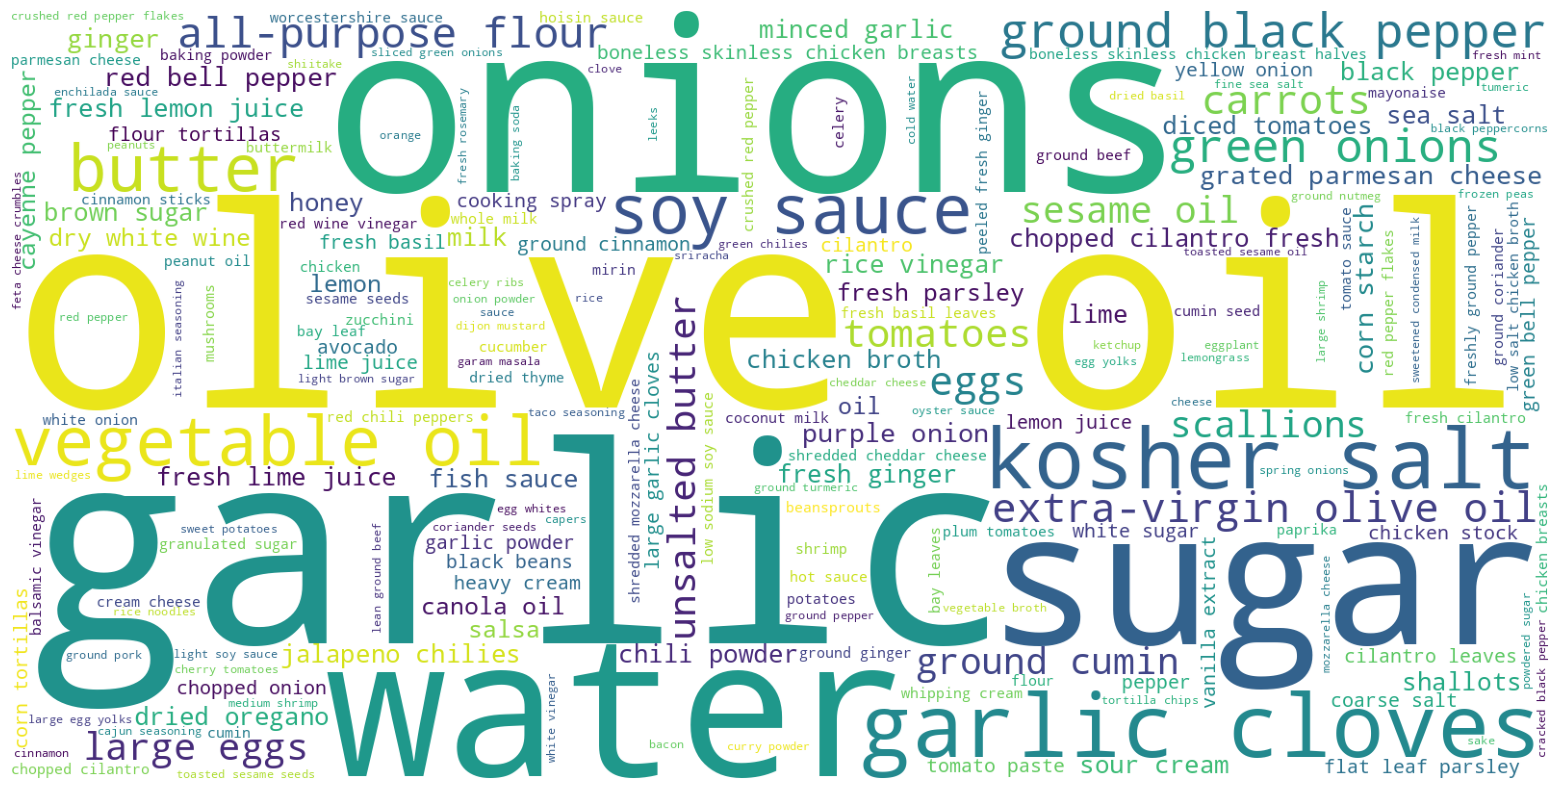

In [ ]:
cloud_0 = WordCloud(
    width=1600, height=800, random_state=0, background_color="white", collocations=False
).generate_from_frequencies(
    pd.Series(ingredients_0.frequency.values, index=ingredients_0.ingredient).to_dict()
)
plt.figure(figsize=(20, 10))
plt.axis("off")
plt.imshow(cloud_0);

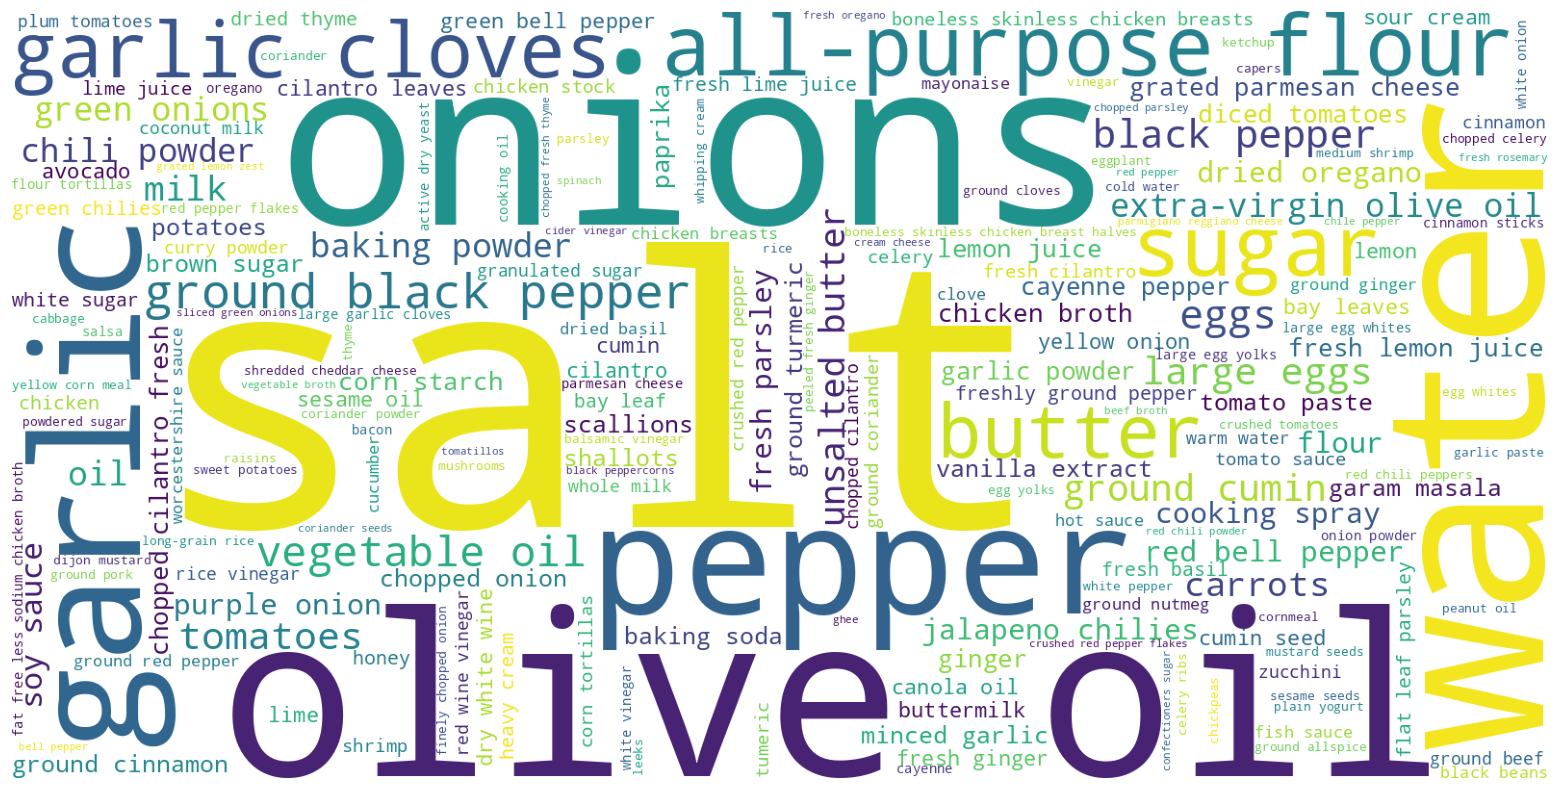

In [ ]:
cloud_1 = WordCloud(
    width=1600, height=800, random_state=0, background_color="white", collocations=False
).generate_from_frequencies(
    pd.Series(ingredients_1.frequency.values, index=ingredients_1.ingredient).to_dict()
)
plt.figure(figsize=(20, 10))
plt.axis("off")
plt.imshow(cloud_1);

Таким образом, в кластере `1` обычная соль используется намного чаще, чем в кластере `0`. В остальном различий практически нет.

## Визуализация и оценка разбиения на плоскости

Применение метода главных компонент с количеством выделяемых признаков 2 для визуализации на плоскости разбиения, полученного с помощью алгоритма кластеризации `KMeans`.

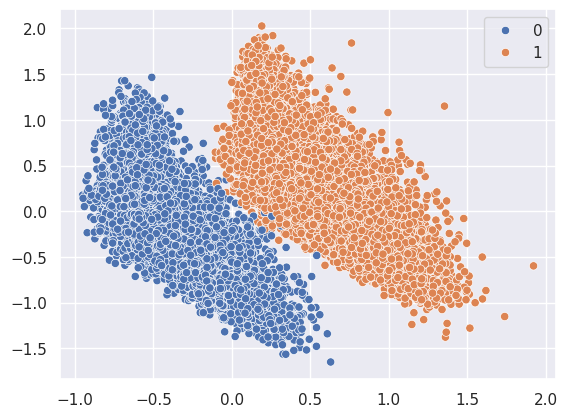

In [ ]:
pca = PCA(2)
X_pca = pca.fit_transform(X_csr)
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=y_pred);

При таком способе подготовки данных все рецепты чётко разделяются на два набора блюд: "пресные" (`0`) и "солёные" (`1`).

Оценка качества кластеризации методом `KMeans` с разделением на 2 кластера с помощью коэффициента силуэта.

In [ ]:
print(silhouette_score(X_pca, y_pred))

0.49645456211895955


## Кластеризация методом DBSCAN

Обучение `DBSCAN` на матрице, полученной с помощью метода главных компонент. Копирование набора данных и добавление столбца, обозначающего кластер, в который был отнесён рецепт. Просмотр количества рецептов, попавших в каждый кластер.

In [ ]:
clustering = DBSCAN(eps=0.045)
y_pred = clustering.fit_predict(X_pca)
recipes_binary = recipes.copy()
recipes_binary["cluster"] = y_pred
recipes_binary_counts = recipes_binary.cluster.value_counts()
print(recipes_binary_counts.sort_index())

cluster
-1       264
 0     21552
 1     17873
 2         8
 3         7
 4        11
 5        11
 6        11
 7         6
 8         5
 9         6
 10        5
 11        6
 12        5
 13        4
Name: count, dtype: int64


Несколько рецептов определились, как выбросы, а ещё меньшее количество рецептов распределились в отдельные маленькие кластеры, т. к. не попали в эпсилон-окрестность крайних точек основных двух кластеров.

Визуализация на плоскости разбиения, полученного с помощью алгоритма кластеризации `DBSCAN`.

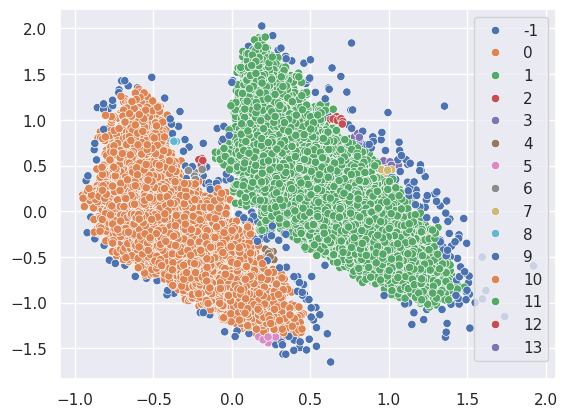

In [ ]:
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=y_pred, palette="deep");

Таким образом, при решении данной задачи использование алгоритма `KMeans` предпочтительнее, т. к. `DBSCAN` сильно зависим от расстояния между кластерами и при задании подходящей эпсилон-окрестности некоторые рецепты считает выбросами.

Оценка качества кластеризации методом `DBSCAN` с помощью коэффициента силуэта.

In [ ]:
print(silhouette_score(X_pca, y_pred))

-0.15233599838502127


## Попытки кластеризации с другим количеством кластеров

Повторное обучение `KMeans` на полученной разреженной матрице с разделением на 3 кластера.

In [ ]:
n_clusters = 3
kmeans_3 = KMeans(n_clusters=n_clusters, random_state=0)
y_pred = kmeans_3.fit_predict(X_csr)
recipes_clustered_3 = recipes.copy()
recipes_clustered_3["cluster"] = y_pred
recipes_clustered_3_counts = recipes_clustered_3.cluster.value_counts()
print(recipes_clustered_3_counts.sort_index())

cluster
0     6225
1    18485
2    15064
Name: count, dtype: int64


Просмотр распределения рецептов каждой кухни по полученным кластерам.

In [ ]:
cuisines = pd.DataFrame(sorted(recipes.cuisine.unique()), columns=["cuisine"])
for i in range(n_clusters):
    cuisines_counts = recipes_clustered_3[recipes_clustered_3.cluster == i].cuisine.value_counts()
    cuisines_i = pd.DataFrame([cuisines_counts.index, cuisines_counts.values]).T
    cuisines_i.rename(columns={0: "cuisine", 1: f"cluster_{i}"}, inplace=True)
    cuisines = pd.merge(cuisines, cuisines_i, on="cuisine")
print(cuisines)

         cuisine cluster_0 cluster_1 cluster_2
0      brazilian        82       246       139
1        british        28       387       389
2   cajun_creole       277       657       612
3        chinese       419      1468       786
4       filipino        91       290       374
5         french       403      1233      1010
6          greek       253       504       418
7         indian       446       888      1669
8          irish        31       279       357
9        italian      1619      3548      2671
10      jamaican       101       162       263
11      japanese        87       941       395
12        korean       170       452       208
13       mexican       919      3287      2232
14      moroccan       223       303       295
15       russian        42       183       264
16   southern_us       297      1898      2125
17       spanish       290       389       310
18          thai       299       921       319
19    vietnamese       148       449       228


При разбиении на 3 кластера рецепты большинства кухонь примерно в равном количестве попали в какие-либо два кластера. Но, например, рецепты азиатской кухни в основном попали в кластер `1`.

Визуализация на плоскости разбиения, полученного с помощью алгоритма кластеризации `KMeans`.

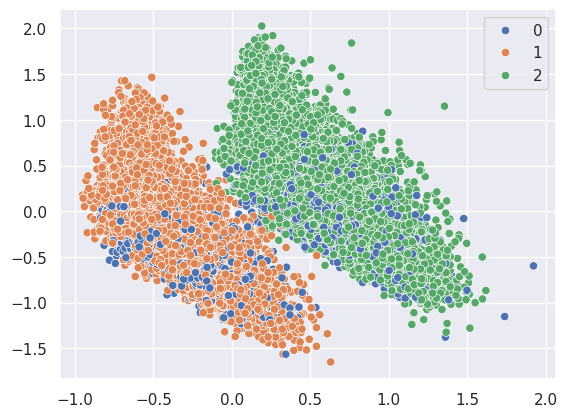

In [ ]:
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=y_pred, palette="deep");

Кластеры `1` и `2` представляют собой кластеры `0` и `1` предыдущего разбиения, а рецепты кластера `0` расположены разреженно.

Оценка качества кластеризации методом `KMeans` с разделением на 3 кластера с помощью коэффициента силуэта.

In [ ]:
print(silhouette_score(X_pca, y_pred))

0.22970567029585


Повторное обучение `KMeans` на полученной разреженной матрице с разделением на 4 кластера.

In [ ]:
n_clusters = 4
kmeans_4 = KMeans(n_clusters=n_clusters, random_state=0)
y_pred = kmeans_4.fit_predict(X_csr)
recipes_clustered_4 = recipes.copy()
recipes_clustered_4["cluster"] = y_pred
recipes_clustered_4_counts = recipes_clustered_4.cluster.value_counts()
print(recipes_clustered_4_counts.sort_index())

cluster
0     2690
1    16474
2    12771
3     7839
Name: count, dtype: int64


Просмотр распределения рецептов каждой кухни по полученным кластерам.

In [ ]:
cuisines = pd.DataFrame(sorted(recipes.cuisine.unique()), columns=["cuisine"])
for i in range(n_clusters):
    cuisines_counts = recipes_clustered_4[recipes_clustered_4.cluster == i].cuisine.value_counts()
    cuisines_i = pd.DataFrame([cuisines_counts.index, cuisines_counts.values]).T
    cuisines_i.rename(columns={0: "cuisine", 1: f"cluster_{i}"}, inplace=True)
    cuisines = pd.merge(cuisines, cuisines_i, on="cuisine")
print(cuisines)

         cuisine cluster_0 cluster_1 cluster_2 cluster_3
0      brazilian        12       229       109       117
1        british        18       363       371        52
2   cajun_creole        45       608       578       315
3        chinese        11      1676       858       128
4       filipino         4       319       386        46
5         french       249      1057       834       506
6          greek       226       262       196       491
7         indian        50       888      1709       356
8          irish        11       262       345        49
9        italian      1345      2134      1306      3053
10      jamaican         6       162       292        66
11      japanese        21       946       403        53
12        korean         4       551       240        35
13       mexican       198      3022      1936      1282
14      moroccan       125       158       133       405
15       russian         6       171       262        50
16   southern_us        93     

При разбиении на 4 кластера рецепты большинства кухонь ещё больше распределились по разным кластерам.

Визуализация на плоскости разбиения, полученного с помощью алгоритма кластеризации `KMeans`.

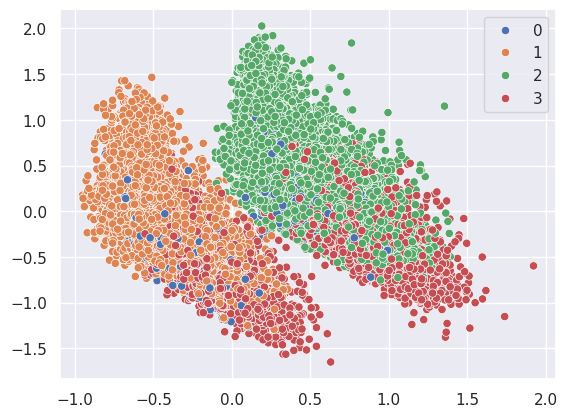

In [ ]:
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=y_pred, palette="deep");

Кластеры `1` и `2` в основном остались без изменений. Рецептов кластера `0` стало значительно меньше и они всё также расположены разреженно. Кластер `3` вобрал в себя все схожие рецепты остальных кластеров.

Оценка качества кластеризации методом `KMeans` с разделением на 4 кластера с помощью коэффициента силуэта.

In [ ]:
print(silhouette_score(X_pca, y_pred))

0.1930710417563867


Повторное обучение `KMeans` на полученной разреженной матрице с разделением на 5 кластеров.

In [ ]:
n_clusters = 5
kmeans_5 = KMeans(n_clusters=n_clusters, random_state=0)
y_pred = kmeans_5.fit_predict(X_csr)
recipes_clustered_5 = recipes.copy()
recipes_clustered_5["cluster"] = y_pred
recipes_clustered_5_counts = recipes_clustered_5.cluster.value_counts()
print(recipes_clustered_5_counts.sort_index())

cluster
0     2590
1    14118
2     9833
3     7665
4     5568
Name: count, dtype: int64


Просмотр распределения рецептов каждой кухни по полученным кластерам.

In [ ]:
cuisines = pd.DataFrame(sorted(recipes.cuisine.unique()), columns=["cuisine"])
for i in range(n_clusters):
    cuisines_counts = recipes_clustered_5[recipes_clustered_5.cluster == i].cuisine.value_counts()
    cuisines_i = pd.DataFrame([cuisines_counts.index, cuisines_counts.values]).T
    cuisines_i.rename(columns={0: "cuisine", 1: f"cluster_{i}"}, inplace=True)
    cuisines = pd.merge(cuisines, cuisines_i, on="cuisine")
print(cuisines)

         cuisine cluster_0 cluster_1 cluster_2 cluster_3 cluster_4
0      brazilian        11       212        57       108        79
1        british        15       324       296        50       119
2   cajun_creole        42       428       360       309       407
3        chinese        10      1517       760       125       261
4       filipino         4       224       202        39       286
5         french       247       960       729       499       211
6          greek       222       241       174       488        50
7         indian        40       611       946       310      1096
8          irish         9       218       279        48       113
9        italian      1319      1940      1117      3033       429
10      jamaican         5       124       181        62       154
11      japanese        20       876       337        51       139
12        korean         4       416       185        32       193
13       mexican       183      2447      1452      1251      

При разбиении на 5 кластеров рецепты большинства кухонь по-прежнему сильно распределены по разным кластерам.

Визуализация на плоскости разбиения, полученного с помощью алгоритма кластеризации `KMeans`.

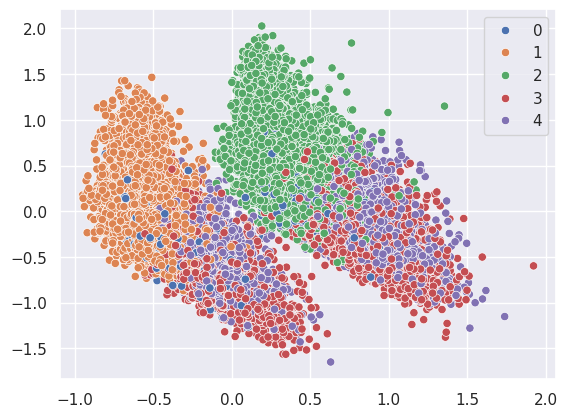

In [ ]:
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=y_pred, palette="deep");

Кластеры `1` и `2` визуально уменьшились в два раза по сравнению с разбиением на три кластера. Кластер `0` в основном остался без изменений. Примерно половина рецептов кластера `3` попали в кластер `4`.

Оценка качества кластеризации методом `KMeans` с разделением на 5 кластеров с помощью коэффициента силуэта.

In [ ]:
print(silhouette_score(X_pca, y_pred))

0.19255082181274927


## Разбиение рецептов на кухни и оценка качества кластеризации

Повторное обучение `KMeans` на полученной разреженной матрице с разделением на 20 кластеров (количество кухонь).

In [ ]:
n_clusters = 20
kmeans_20 = KMeans(n_clusters=n_clusters, random_state=0)
y_pred = kmeans_20.fit_predict(X_csr)
recipes_clustered_20 = recipes.copy()
recipes_clustered_20["cluster"] = y_pred
recipes_clustered_20_counts = recipes_clustered_20.cluster.value_counts()
print(recipes_clustered_20_counts.sort_index())

cluster
0        1
1      508
2     1412
3     1152
4     1989
5     1339
6     1220
7     3521
8     2450
9      985
10     618
11    7377
12    2595
13    2142
14    1808
15    1087
16    2968
17    3082
18    1098
19    2422
Name: count, dtype: int64


Оценка качества кластеризации методом `KMeans` с разделением на 20 кластеров с помощью коэффициента силуэта.

In [ ]:
print(silhouette_score(X_pca, y_pred))

-0.1944068836884371


Оценка качества кластеризации, исходя из предположения, что `cuisine` (кухня) — истинная метка принадлежности кластеру.

In [ ]:
print(adjusted_rand_score(y_true, y_pred))

0.05072980528685664


# Разбиение на понятия

В первом способе названия ингредиентов используются целиком, за счёт чего возникает множество логических неточностей, например: `garlic` и `garlic cloves` в контексте ингредиентов ничем не отличаются. Исходя из этого, другой способ подготовки данных будет заключаться в разбиении названий ингредиентов на слова, что должно обобщить схожие понятия.

In [ ]:
count_vectorizer = CountVectorizer()
X_csr = count_vectorizer.fit_transform(X)
ingredients = pd.DataFrame(count_vectorizer.get_feature_names_out(), columns=["ingredient"])
ingredients["frequency"] = X_csr.sum(axis=0).T
ingredients.sort_values("frequency", ascending=False, inplace=True)
ingredients.reset_index(drop=True, inplace=True)
ingredients.head(10)

,ingredient,frequency
0,pepper,25742
1,salt,24462
2,oil,23344
3,garlic,18941
4,ground,18271
5,fresh,17853
6,sauce,13129
7,sugar,12493
8,onions,12341
9,cheese,11776


При таком способе разбиения названий ингредиентов чаще всего в рецептах встречаются следующие понятия: `pepper` (перец), `salt` (соль), `oil` (масло), `garlic` (чеснок), `ground` (молотый), `fresh` (свежий), `sauce` (соус), `sugar` (сахар), `onions` (лук), `cheese` (сыр).

## Кластеризация методом k-средних

Повторное обучение `KMeans` на полученной разреженной матрице с разделением на 2 кластера.

In [ ]:
n_clusters = 2
kmeans_2 = KMeans(n_clusters=n_clusters, random_state=5)
y_pred = kmeans_2.fit_predict(X_csr)
recipes_clustered_2 = recipes.copy()
recipes_clustered_2["cluster"] = y_pred
recipes_clustered_2.cluster.value_counts()

,count
cluster,
0,22288
1,17486


Просмотр распределения рецептов каждой кухни по полученным кластерам.

In [ ]:
cuisines = pd.DataFrame(sorted(recipes.cuisine.unique()), columns=["cuisine"])
for i in range(n_clusters):
    cuisines_counts = recipes_clustered_2[recipes_clustered_2.cluster == i].cuisine.value_counts()
    cuisines_i = pd.DataFrame([cuisines_counts.index, cuisines_counts.values]).T
    cuisines_i.rename(columns={0: "cuisine", 1: f"cluster_{i}"}, inplace=True)
    cuisines = pd.merge(cuisines, cuisines_i, on="cuisine")
print(cuisines)

         cuisine cluster_0 cluster_1
0      brazilian       294       173
1        british       687       117
2   cajun_creole       521      1025
3        chinese      1440      1233
4       filipino       460       295
5         french      1835       811
6          greek       473       702
7         indian      1360      1643
8          irish       546       121
9        italian      3811      4027
10      jamaican       210       316
11      japanese      1169       254
12        korean       499       331
13       mexican      3476      2962
14      moroccan       218       603
15       russian       377       112
16   southern_us      3253      1067
17       spanish       422       567
18          thai       775       764
19    vietnamese       462       363


При разбиении на 2 кластера рецепты большинства кухонь примерно в равном количестве попали в каждый кластер.

Аналогичное получение разреженных матриц ингредиентов для кластеров `0` и `1` по отдельности.

In [ ]:
recipes_0 = recipes_clustered_2[recipes_clustered_2.cluster == 0]
recipes_0.reset_index(drop=True, inplace=True)
X_0 = recipes_0.ingredients.apply(lambda x: " ".join(map(str, x)))
count_vectorizer_0 = CountVectorizer()
X_csr_0 = count_vectorizer_0.fit_transform(X_0)
X_csr_0

<Compressed Sparse Row sparse matrix of dtype 'int64'
	with 338079 stored elements and shape (22288, 2730)>

In [ ]:
recipes_1 = recipes_clustered_2[recipes_clustered_2.cluster == 1]
recipes_1.reset_index(drop=True, inplace=True)
X_1 = recipes_1.ingredients.apply(lambda x: " ".join(map(str, x)))
count_vectorizer_1 = CountVectorizer()
X_csr_1 = count_vectorizer_1.fit_transform(X_1)
X_csr_1

<Compressed Sparse Row sparse matrix of dtype 'int64'
	with 423872 stored elements and shape (17486, 2313)>

Аналогичный вывод десяти ингредиентов, наиболее часто встречающихся в каждом кластере.

In [ ]:
ingredients_0 = pd.DataFrame(count_vectorizer_0.get_feature_names_out(), columns=["ingredient"])
ingredients_0["frequency"] = X_csr_0.sum(axis=0).T
ingredients_0.sort_values("frequency", ascending=False, inplace=True)
ingredients_0.reset_index(drop=True, inplace=True)
ingredients_0.head(10)

,ingredient,frequency
0,salt,10565
1,sugar,9457
2,oil,8356
3,flour,6334
4,cheese,6330
5,sauce,6158
6,butter,6118
7,water,5617
8,garlic,5327
9,fresh,5114


При таком способе разбиения чаще всего в рецептах кластера `0` встречаются следующие понятия: `salt` (соль), `sugar` (сахар), `oil` (масло), `flour` (мука), `cheese` (сыр), `sauce` (соус), `butter` (сливочное масло), `water` (вода), `garlic` (чеснок), `fresh` (свежий).

In [ ]:
ingredients_1 = pd.DataFrame(count_vectorizer_1.get_feature_names_out(), columns=["ingredient"])
ingredients_1["frequency"] = X_csr_1.sum(axis=0).T
ingredients_1.sort_values("frequency", ascending=False, inplace=True)
ingredients_1.reset_index(drop=True, inplace=True)
ingredients_1.head(10)

,ingredient,frequency
0,pepper,21270
1,oil,14988
2,ground,14623
3,salt,13897
4,garlic,13614
5,fresh,12739
6,black,8704
7,olive,8127
8,onions,7993
9,chicken,7489


При таком способе разбиения чаще всего в рецептах кластера `1` встречаются следующие понятия: `pepper` (перец), `oil` (масло), `ground` (молотый), `salt` (соль), `garlic` (чеснок), `fresh` (свежий), `black` (чёрный), `olive` (оливковый), `onions` (лук), `ckicken` (курица).

Таким образом, кластеры по своему составу различаются значительно больше, чем при первом способе разбиения.

## Визуализация разбиения с помощью облаков слов

Повторная ненерация изображений облаков слов из полученных списков ингредиентов для каждого кластера.

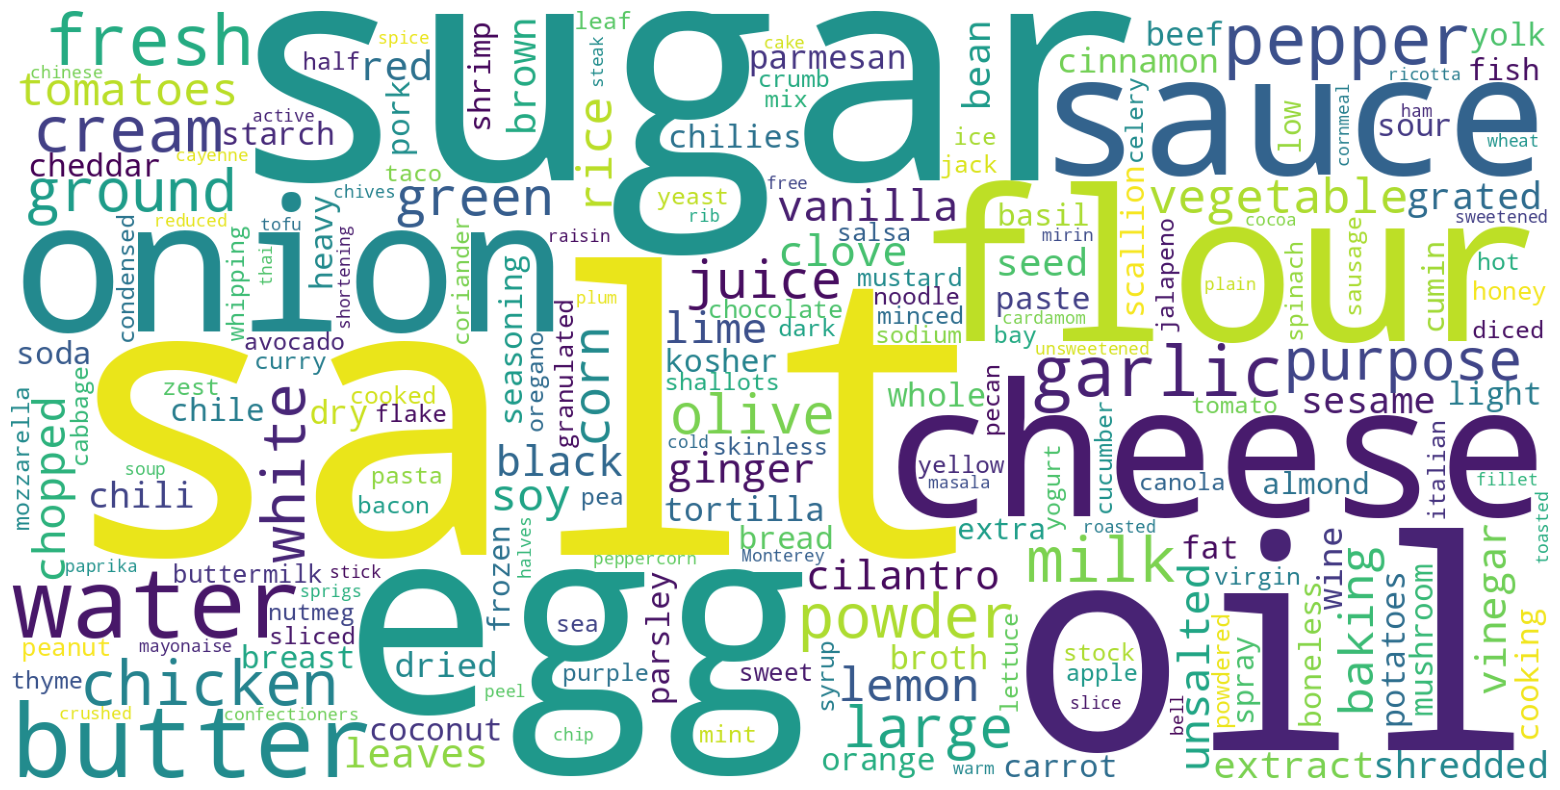

In [ ]:
cloud_0 = WordCloud(
    width=1600, height=800, random_state=0, background_color="white", collocations=False
).generate(
    " ".join([" ".join(i) for i in recipes_0.ingredients])
)
plt.figure(figsize=(20, 10))
plt.axis("off")
plt.imshow(cloud_0);

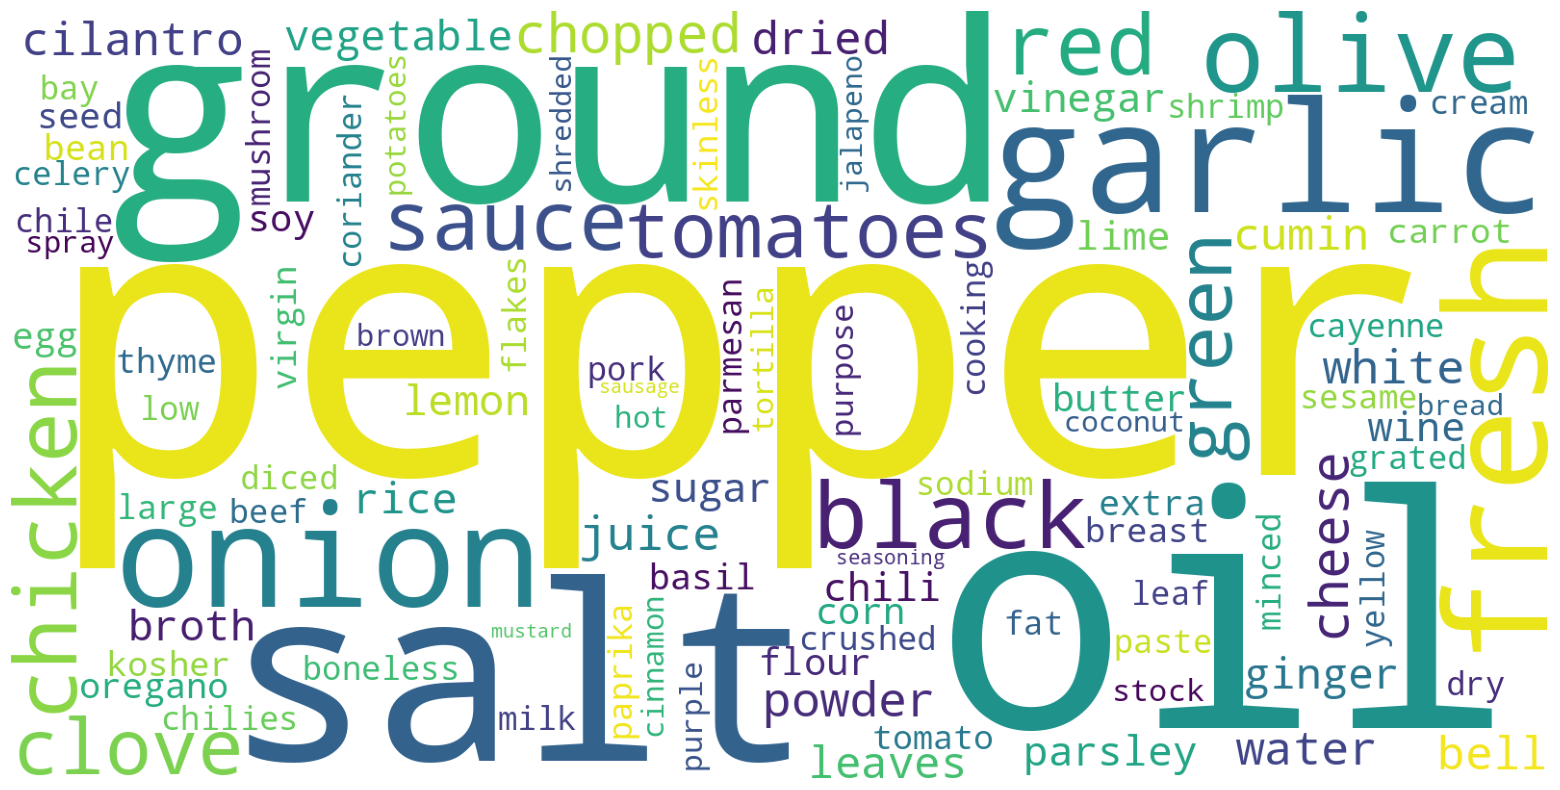

In [ ]:
cloud_1 = WordCloud(
    width=1600, height=800, max_words=100, random_state=0, background_color="white", collocations=False
).generate(
    " ".join([" ".join(i) for i in recipes_1.ingredients])
)
plt.figure(figsize=(20, 10))
plt.axis("off")
plt.imshow(cloud_1);

При таком способе разбиения названий ингредиентов различия между кластерами видны более явно.

Кластер `0` больше похож на выпечку, исходя из следующих понятий: `sugar` (сахар), `oil` (масло), `egg` (яйцо), `flour` (мука), `cheese` (сыр), `butter` (сливочное масло), `water` (вода), `milk` (молоко), `cream` (сливки), `powder` (пудра).

Кластер `1` больше похож на блюда с овощами или мясом, исходя из следующих понятий: `pepper` (перец), `salt` (соль), `ground` (молотый), `garlic` (чеснок), `onion` (лук), `fresh` (свежий), `chicken` (курица), `olive` (оливковый), `sauce` (соус), `tomatoes` (томаты).

## Визуализация и оценка разбиения на плоскости

Применение метода главных компонент с количеством выделяемых признаков 2 для визуализации разбиения на плоскости.

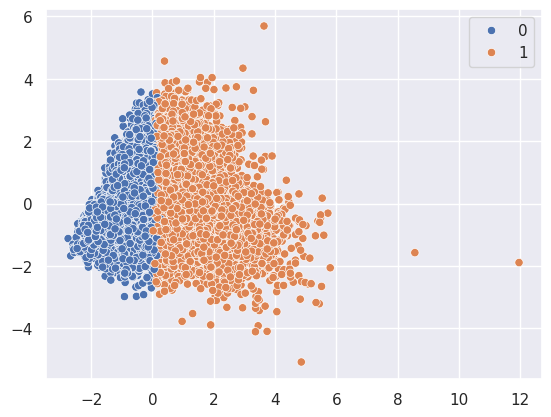

In [ ]:
pca = PCA(2)
X_pca = pca.fit_transform(X_csr)
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=y_pred);

Исходя из облаков слов, кластер `0` больше похож на выпечку, а кластер `1` на блюда с овощами или мясом.

Оценка качества кластеризации методом `KMeans` с разделением на 2 кластера с помощью коэффициента силуэта.

In [ ]:
print(silhouette_score(X_pca, y_pred))

0.38264205547327906


## Кластеризация методом DBSCAN

Обучение `DBSCAN` на матрице, полученной с помощью метода главных компонент. Копирование набора данных и добавление столбца, обозначающего кластер, в который был отнесён рецепт. Просмотр количества рецептов, попавших в каждый кластер.

In [ ]:
clustering = DBSCAN(eps=0.3)
y_pred = clustering.fit_predict(X_pca)
recipes_binary = recipes.copy()
recipes_binary["cluster"] = y_pred
recipes_binary_counts = recipes_binary.cluster.value_counts()
print(recipes_binary_counts.sort_index())

cluster
-1       47
 0    39710
 1        5
 2        5
 3        7
Name: count, dtype: int64


Несколько рецептов определились, как выбросы, а ещё меньшее количество рецептов распределились в отдельные маленькие кластеры, т. к. не попали в эпсилон-окрестность крайних точек основного кластера.

Визуализация на плоскости разбиения, полученного с помощью алгоритма кластеризации `DBSCAN`.

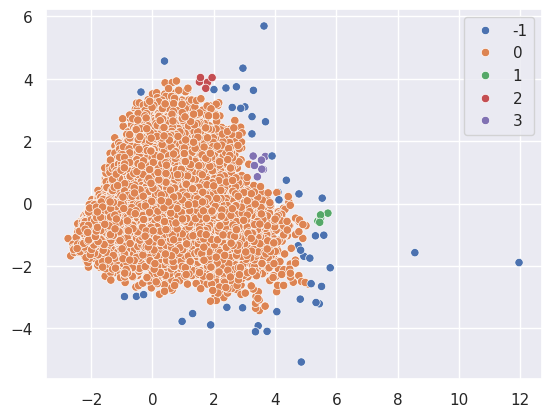

In [ ]:
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=y_pred, palette="deep");

Таким образом, при решении данной задачи использование алгоритма `KMeans` предпочтительнее, т. к. `DBSCAN` в силу своей реализации неспособен разделить рецепты в таком представлении на два кластера.

Оценка качества кластеризации методом `DBSCAN` с помощью коэффициента силуэта.

In [ ]:
print(silhouette_score(X_pca, y_pred))

0.45883568371803657


## Попытки кластеризации с другим количеством кластеров

Повторное обучение `KMeans` на полученной разреженной матрице с разделением на 3 кластера.

In [ ]:
n_clusters = 3
kmeans_3 = KMeans(n_clusters=n_clusters, random_state=0)
y_pred = kmeans_3.fit_predict(X_csr)
recipes_clustered_3 = recipes.copy()
recipes_clustered_3["cluster"] = y_pred
recipes_clustered_3_counts = recipes_clustered_3.cluster.value_counts()
print(recipes_clustered_3_counts.sort_index())

cluster
0     5822
1    14826
2    19126
Name: count, dtype: int64


Просмотр распределения рецептов каждой кухни по полученным кластерам.

In [ ]:
cuisines = pd.DataFrame(sorted(recipes.cuisine.unique()), columns=["cuisine"])
for i in range(n_clusters):
    cuisines_counts = recipes_clustered_3[recipes_clustered_3.cluster == i].cuisine.value_counts()
    cuisines_i = pd.DataFrame([cuisines_counts.index, cuisines_counts.values]).T
    cuisines_i.rename(columns={0: "cuisine", 1: f"cluster_{i}"}, inplace=True)
    cuisines = pd.merge(cuisines, cuisines_i, on="cuisine")
print(cuisines)

         cuisine cluster_0 cluster_1 cluster_2
0      brazilian         8       169       290
1        british         6       116       682
2   cajun_creole        77       964       505
3        chinese      2186        86       401
4       filipino       324       129       302
5         french        11       837      1798
6          greek         5       720       450
7         indian        57      1638      1308
8          irish         5       121       541
9        italian        33      4125      3680
10      jamaican        60       271       195
11      japanese       646        86       691
12        korean       611        31       188
13       mexican       114      2954      3370
14      moroccan         2       610       209
15       russian         5       110       374
16   southern_us        95      1029      3196
17       spanish         8       575       406
18          thai      1034       183       322
19    vietnamese       535        72       218


Так, кластер `0` в основном составляют рецепты азиатской кухни: китайская (`chinese`), тайская (`thai`), корейская (`korean`), вьетнамская (`vietnamese`). Большинство рецептов луизианской кухни (`cajun_creole`), греческой кухни (`greek`) и марокканской кухни (`moroccan`) попали в кластер `1`. Большинство рецептов британской кухни (`british`), французской кухни (`french`), ирландской кухни (`irish`), русской кухни (`russian`) и южноамериканской кухни (`southern_us`) попали в кластер `2`. Рецепты каждой из оставшихся кухонь сильно разнесены по разным кластерам.

Визуализация на плоскости разбиения, полученного с помощью алгоритма кластеризации `KMeans`.

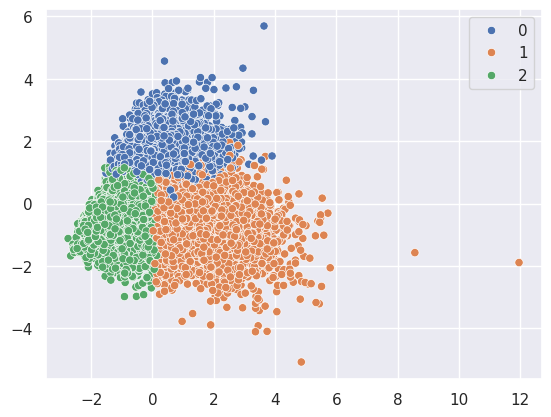

In [ ]:
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=y_pred, palette="deep");

Исходя из полученной ранее таблицы, кластер `0` представляет азиатскую кухню, кластер `2` в основном составляет европейская и американская кухни, а в кластере `1` смешаны остальные кухни.

Оценка качества кластеризации методом `KMeans` с разделением на 3 кластера с помощью коэффициента силуэта.

In [ ]:
print(silhouette_score(X_pca, y_pred))

0.40842918727652916


Повторное обучение `KMeans` на полученной разреженной матрице с разделением на 4 кластера.

In [ ]:
n_clusters = 4
kmeans_4 = KMeans(n_clusters=n_clusters, random_state=0)
y_pred = kmeans_4.fit_predict(X_csr)
recipes_clustered_4 = recipes.copy()
recipes_clustered_4["cluster"] = y_pred
recipes_clustered_4_counts = recipes_clustered_4.cluster.value_counts()
print(recipes_clustered_4_counts.sort_index())

cluster
0    10679
1     6960
2    16435
3     5700
Name: count, dtype: int64


Просмотр распределения рецептов каждой кухни по полученным кластерам.

In [ ]:
cuisines = pd.DataFrame(sorted(recipes.cuisine.unique()), columns=["cuisine"])
for i in range(n_clusters):
    cuisines_counts = recipes_clustered_4[recipes_clustered_4.cluster == i].cuisine.value_counts()
    cuisines_i = pd.DataFrame([cuisines_counts.index, cuisines_counts.values]).T
    cuisines_i.rename(columns={0: "cuisine", 1: f"cluster_{i}"}, inplace=True)
    cuisines = pd.merge(cuisines, cuisines_i, on="cuisine")
print(cuisines)

         cuisine cluster_0 cluster_1 cluster_2 cluster_3
0      brazilian       101        92       267         7
1        british        71        68       659         6
2   cajun_creole       305       716       454        71
3        chinese        57        67       374      2175
4       filipino        54        98       284       319
5         french       896       158      1581        11
6          greek       726       149       296         4
7         indian       556      1247      1152        48
8          irish        80        49       534         4
9        italian      4625       640      2549        24
10      jamaican        68       224       182        52
11      japanese        48        66       662       647
12        korean        19        18       177       616
13       mexican      1498      1979      2863        98
14      moroccan       278       392       150         1
15       russian        76        43       364         6
16   southern_us       481     

Получаем, что кластер `3` в основном составляют рецепты азиатской кухни: китайская (`chinese`), тайская (`thai`), корейская (`korean`), вьетнамская (`vietnamese`). Кластер `2` в основном составляют рецепты европейской и американской кухни: британская (`british`), французская (`french`), ирландская (`irish`), русская (`russian`) и южноамериканская (`southern_us`) попали в кластер `2`. Большинство рецептов греческой кухни (`greek`), итальянской кухни (`italian`) и испанской кухни (`spanish`) попали в кластер `0`. Другие кухни по-прежнему сильно разнесены по кластерам.

Визуализация на плоскости разбиения, полученного с помощью алгоритма кластеризации `KMeans`.

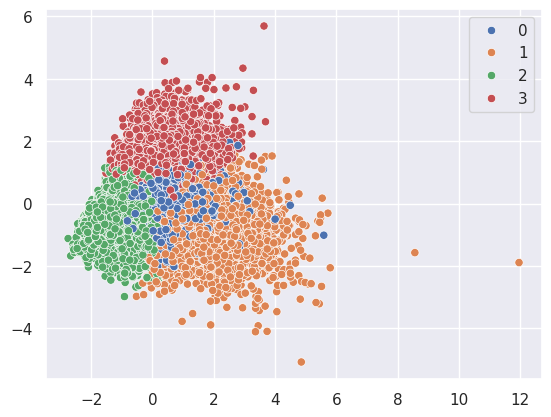

In [ ]:
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=y_pred, palette="deep");

Исходя из полученной ранее таблицы, кластер `3` представляет азиатскую кухню, кластер `2` в основном составляет европейская и американская кухни, а в кластерах `1` и `0` по-прежнему смешаны остальные кухни.

Оценка качества кластеризации методом `KMeans` с разделением на 4 кластера с помощью коэффициента силуэта.

In [ ]:
print(silhouette_score(X_pca, y_pred))

0.2494406168276773


Повторное обучение `KMeans` на полученной разреженной матрице с разделением на 5 кластеров.

In [ ]:
n_clusters = 5
kmeans_5 = KMeans(n_clusters=n_clusters, random_state=0)
y_pred = kmeans_5.fit_predict(X_csr)
recipes_clustered_5 = recipes.copy()
recipes_clustered_5["cluster"] = y_pred
recipes_clustered_5_counts = recipes_clustered_5.cluster.value_counts()
print(recipes_clustered_5_counts.sort_index())

cluster
0    14567
1     6424
2     4893
3     5234
4     8656
Name: count, dtype: int64


Просмотр распределения рецептов каждой кухни по полученным кластерам.

In [ ]:
cuisines = pd.DataFrame(sorted(recipes.cuisine.unique()), columns=["cuisine"])
for i in range(n_clusters):
    cuisines_counts = recipes_clustered_5[recipes_clustered_5.cluster == i].cuisine.value_counts()
    cuisines_i = pd.DataFrame([cuisines_counts.index, cuisines_counts.values]).T
    cuisines_i.rename(columns={0: "cuisine", 1: f"cluster_{i}"}, inplace=True)
    cuisines = pd.merge(cuisines, cuisines_i, on="cuisine")
print(cuisines)

         cuisine cluster_0 cluster_1 cluster_2 cluster_3 cluster_4
0      brazilian       273        88        33         4        69
1        british       337        62       349         3        53
2   cajun_creole       436       687       140        55       228
3        chinese       386        64        67      2126        30
4       filipino       287        87        72       283        26
5         french       962       134       756         8       786
6          greek       294       134        86         3       658
7         indian      1320      1170       131        30       352
8          irish       311        44       246         4        62
9        italian      2467       515       687        10      4159
10      jamaican       165       215        59        48        39
11      japanese       673        56        87       573        34
12        korean       197        16        19       592         6
13       mexican      3416      1853       262        59      

Большинство рецептов одних и тех же кухонь стали попадать в большее количество кластеров с увеличением их числа. Вероятнее всего, это говорит о том, что многие кухни содержат в себе различные группы рецептов, похожие на разные кухни других культур, из-за чего каждый кластер больше показывает набор схожих рецептов, чем схожие культуры.

Визуализация на плоскости разбиения, полученного с помощью алгоритма кластеризации `KMeans`.

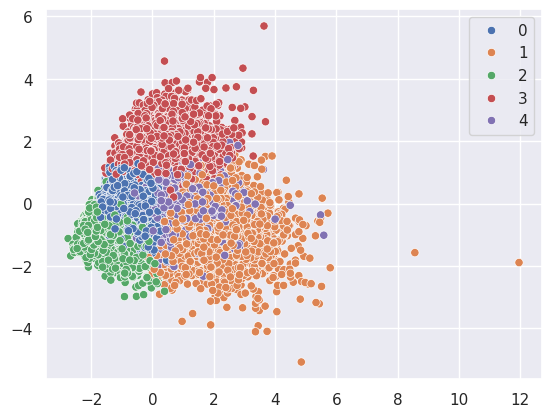

In [ ]:
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=y_pred, palette="deep");

Кластер `3`, представляющий азиатскую кухню остаётся практически без изменений. А все остальные кластеры сильно перемешаны между собой и продолжать увеличивать их количество не имеет смысла.

Оценка качества кластеризации методом `KMeans` с разделением на 5 кластеров с помощью коэффициента силуэта.

In [ ]:
print(silhouette_score(X_pca, y_pred))

0.16666802975725015


## Разбиение рецептов на кухни и оценка качества кластеризации

Повторное обучение `KMeans` на полученной разреженной матрице с разделением на 20 кластеров (количество кухонь).

In [ ]:
n_clusters = 20
kmeans_20 = KMeans(n_clusters=n_clusters, random_state=0)
y_pred = kmeans_20.fit_predict(X_csr)
recipes_clustered_20 = recipes.copy()
recipes_clustered_20["cluster"] = y_pred
recipes_clustered_20_counts = recipes_clustered_20.cluster.value_counts()
print(recipes_clustered_20_counts.sort_index())

cluster
0     3440
1     1525
2     1345
3     2130
4     1128
5     3322
6     5763
7     1397
8     1446
9     1368
10    1107
11    1474
12    1842
13    1725
14    1610
15    2274
16    2073
17    2025
18    1439
19    1341
Name: count, dtype: int64


Оценка качества кластеризации методом `KMeans` с разделением на 20 кластеров с помощью коэффициента силуэта.

In [ ]:
print(silhouette_score(X_pca, y_pred))

-0.05678095176575088


Оценка качества кластеризации, исходя из предположения, что `cuisine` (кухня) — истинная метка принадлежности кластеру.

In [ ]:
print(adjusted_rand_score(y_true, y_pred))

0.10756150533423454


# Вывод о кластеризации представленного набора данных

Во-первых, в данном случае эффективнее разбивать состав рецептов не на конкретные ингредиенты, а на понятия, встречающиеся в названиях ингредиентов. Это объясняется большим количеством схожих по названию ингредиентов или даже разных названий одних и тех же ингредиентов, таких как: соль, перец, мука и т. п.

Во-вторых, алгоритм кластеризации `KMeans` предпочтительнее, чем `DBSCAN`, для разбиения этого набора данных, т. к. `DBSCAN` имеет плохое качество кластеризации на скученных данных, в отличие от `KMeans`.

В-третьих, коэффициент силуэта недостаточно объективно показывает качество кластеризации и является очень примерной оценкой. Скорректированный индекс Рэнда показывает более достоверную оценку качества кластеризации, т. к. действительно второй способ разбиения состава рецептов оказывается эффективнее. Но ещё более эффективной является оценка, исходя из таблиц распределения рецептов каждой кухни по полученным кластерам.

Таким образом, лучше всего отделяются рецепты азиатской кухни, что, вероятнее всего, связано с уникальными ингредиентами, которые традиционно намного реже используются в других культурах. Также, неплохо отделяются рецепты европейской и американской кухни, которые в общем тоже имеют сходства и характерные им ингредиенты. Рецепты остальных кухонь достаточно сильно смешаны и разбиваются неэффективно.